# KAN Pilot — Metode Pembanding (Kolmogorov-Arnold Network) untuk ECG 187-point

**Status notebook: BELUM DIJALANKAN.** Notebook ini dibuat tanpa akses ke Google Drive dan GPU. Semua flag default `False`.

**Bukan replikasi exact.** Paper Cui et al. (2025, *Algorithms* 18(2):90, DOI `10.3390/a18020090`) hanya dipakai sebagai inspirasi metodologi.

Paper-reported (diverifikasi dari teks lengkap MDPI, **bukan hasil eksperimen ini**):
Accuracy 99.08%, Precision 99.07%, Recall 98.99%, F1 99.03%. Protokol split paper tidak dijelaskan, sehingga angka ini **tidak dapat dibandingkan langsung** dengan baseline.

Baseline (proyek): ResNet18 + GAF, Accuracy 98.86%, Macro P 95.23%, Macro R 91.97%, Macro F1 93.53%.
**Perhatian:** angka baseline ini berasal dari checkpoint yang dipilih berdasarkan **test set** (notebook `01_replikasi`, Tabel A). Lihat sel perbandingan.

**Urutan wajib:** smoke test → pilot 10 epoch → keputusan pilot → (hanya jika PROMISING) full training 150 epoch → evaluasi test sekali.

In [18]:
# ===== CONFIG & FLAGS =====
import os

# Default semua False. Membuka/Run All notebook TIDAK memulai training.
RUN_SMOKE_TEST = False
RUN_PILOT = True
RUN_FULL_TRAINING = False
RUN_FINAL_EVALUATION = False
RESUME = False

SEED = 42
BASE_DIR = "/content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion"
DATA_CSV = os.path.join(BASE_DIR, "data", "mitbih_train.csv")
FEAT_DIR = os.path.join(BASE_DIR, "features")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints", "kan")
RESULTS_DIR = os.path.join(BASE_DIR, "outputs", "results")
FIG_DIR = os.path.join(BASE_DIR, "outputs", "figures")

N_FEAT = 187
N_CLASSES = 5
CLASS_NAMES = ["N", "S", "V", "F", "Q"]
EXPECTED_TRAIN_COUNTS = {0: 72471, 1: 2223, 2: 5788, 3: 641, 4: 6431}
EXPECTED_TEST_COUNTS = {0: 18118, 1: 556, 2: 1448, 3: 162, 4: 1608}

# Parameter dari paper (Cui et al. 2025, Sec. 4.1 dan 3.4)
VAL_SIZE = 0.2
HIDDEN = 128
LR = 5e-5
BATCH_SIZE = 64
EPOCHS_PILOT = 10
EPOCHS_FULL = 150
GRID_RANGE = (-1.0, 1.0)
SPLINE_ORDER = 2           # paper: "quadratic spline"
SCALE_SPLINE = 1.0
GRID_EPS = 0.02            # dicatat dari paper, TIDAK DITERAPKAN (lihat KANLayer)

# ASUMSI (tidak ada di paper)
GRID_SIZE = 5              # jumlah interval grid
PILOT_TOLERANCE_PP = 2.0   # heuristik keputusan pilot, bukan dari paper

BASELINE = {"accuracy": 98.86, "macro_precision": 95.23, "macro_recall": 91.97, "macro_f1": 93.53}
BASELINE_PARAMS_TOTAL = 11341125

# Hasil keputusan (diisi saat cell dijalankan)
PILOT_DECISION = None
COMPARISON_DECISION = None
FINAL = None
SMOKE_STATUS = None

In [19]:
# ===== ENVIRONMENT =====
import json, math, random, time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)
from sklearn.model_selection import train_test_split
from google.colab import drive

drive.mount("/content/drive")
for d in (CKPT_DIR, RESULTS_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("torch", torch.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__, "| device", DEVICE)
if DEVICE.type == "cuda":
    print("GPU", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
torch 2.14.1+cu130 | numpy 2.4.6 | sklearn 1.6.1 | device cuda
GPU Tesla T4


## 1. Data
Train dibaca dari `data/mitbih_train.csv` (diasumsikan tanpa header; assert shape akan gagal jika salah).
Test dibaca dari `features/X_test.npy` dan **hanya dipakai pada evaluasi final**.

In [20]:
# ===== LOAD RAW TRAIN CSV & TEST (features) =====
raw = pd.read_csv(DATA_CSV, header=None)
assert raw.shape == (87554, N_FEAT + 1), f"Shape CSV tidak sesuai: {raw.shape}. Cek apakah ada header."
X_raw = raw.iloc[:, :N_FEAT].to_numpy(dtype=np.float32)
y_raw = raw.iloc[:, N_FEAT].to_numpy().astype(np.int64)
del raw

assert set(np.unique(y_raw).tolist()) == set(range(N_CLASSES))
cnt_train = dict(sorted(Counter(y_raw.tolist()).items()))
assert cnt_train == EXPECTED_TRAIN_COUNTS, cnt_train

X_test = np.load(os.path.join(FEAT_DIR, "X_test.npy")).astype(np.float32)
y_test = np.load(os.path.join(FEAT_DIR, "y_test.npy")).astype(np.int64)
assert X_test.shape == (21892, N_FEAT) and y_test.shape == (21892,)
assert dict(sorted(Counter(y_test.tolist()).items())) == EXPECTED_TEST_COUNTS

for name, a in (("train raw", X_raw), ("test", X_test)):
    print(f"{name:10s} shape={a.shape} min={a.min():.4f} max={a.max():.4f} finite={bool(np.isfinite(a).all())}")

train raw  shape=(87554, 187) min=0.0000 max=1.0000 finite=True
test       shape=(21892, 187) min=0.0000 max=1.0000 finite=True


## 2. Split 80/20 stratified (train raw saja) dan balancing (training split saja)
Validation dan test **tidak** di-balance. Balancing memakai random oversampling dengan replacement, dibuat sebagai indeks (tanpa file baru).

In [21]:
# ===== STRATIFIED SPLIT =====
idx_all = np.arange(len(y_raw))
idx_tr, idx_va = train_test_split(idx_all, test_size=VAL_SIZE, stratify=y_raw, random_state=42)
print("training split  :", len(idx_tr))
print("validation split:", len(idx_va))

# ===== BALANCING (training split saja) =====
def oversample_to_majority(idx, y, seed):
    rs = np.random.RandomState(seed)
    counts = Counter(y[idx].tolist())
    target = max(counts.values())
    parts = [idx]
    for c in range(N_CLASSES):
        cls_idx = idx[y[idx] == c]
        extra = target - len(cls_idx)
        if extra > 0:
            parts.append(rs.choice(cls_idx, size=extra, replace=True))
    bal = np.concatenate(parts)
    rs.shuffle(bal)
    return bal, dict(sorted(counts.items())), target

bal_idx, counts_before, target = oversample_to_majority(idx_tr, y_raw, seed=SEED)
counts_after = dict(sorted(Counter(y_raw[bal_idx].tolist()).items()))
print("before balancing:", counts_before)
print("after balancing :", counts_after, "| target =", target)

pd.DataFrame({
    "class": CLASS_NAMES,
    "train_before_balance": [counts_before.get(c, 0) for c in range(N_CLASSES)],
    "train_after_balance": [counts_after.get(c, 0) for c in range(N_CLASSES)],
    "validation": [int((y_raw[idx_va] == c).sum()) for c in range(N_CLASSES)],
}).to_csv(os.path.join(RESULTS_DIR, "kan_class_distribution.csv"), index=False)

training split  : 70043
validation split: 17511
before balancing: {0: 57977, 1: 1778, 2: 4630, 3: 513, 4: 5145}
after balancing : {0: 57977, 1: 57977, 2: 57977, 3: 57977, 4: 57977} | target = 57977


## 3. Variance sorting (dihitung dari training split saja)
Variance dihitung **hanya** dari data training yang sudah di-balance. Urutan yang sama diterapkan ke validation dan test. Arah urutan (naik/turun) tidak disebut paper; di sini dipilih **naik** (ASUMSI, dicatat di metadata).

In [22]:
# ===== VARIANCE SORTING (training split saja) =====
var_train = np.var(X_raw[bal_idx], axis=0, dtype=np.float64)
feature_order = np.argsort(var_train)  # ASUMSI: urutan naik
assert sorted(feature_order.tolist()) == list(range(N_FEAT))

np.save(os.path.join(RESULTS_DIR, "kan_variance_order.npy"), feature_order)
with open(os.path.join(RESULTS_DIR, "kan_variance_order_meta.json"), "w") as f:
    json.dump({
        "source": "training split only (balanced), no validation or test used",
        "n_samples_used": int(len(bal_idx)),
        "order_direction": "ascending (ASSUMPTION, paper does not specify)",
        "n_features": N_FEAT,
    }, f, indent=2)

X_all_p = X_raw[:, feature_order]
X_test_p = X_test[:, feature_order]
print("feature_order saved. min variance =", float(var_train.min()), "| max variance =", float(var_train.max()))

feature_order saved. min variance = 0.0039049787258852654 | max variance = 0.07933895486076703


## 4. DataLoader (berbasis indeks, tanpa file dataset baru)

In [23]:
class IndexedArrayDataset(Dataset):
    def __init__(self, X, y, idx):
        self.X, self.y, self.idx = X, y, np.asarray(idx)

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        return torch.from_numpy(self.X[j]), int(self.y[j])

train_ds = IndexedArrayDataset(X_all_p, y_raw, bal_idx)
val_ds = IndexedArrayDataset(X_all_p, y_raw, idx_va)
test_ds = IndexedArrayDataset(X_test_p, y_test, np.arange(len(y_test)))

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print("train/val/test samples:", len(train_ds), len(val_ds), len(test_ds))

train/val/test samples: 289885 17511 21892


## 5. Model KAN 187 → 128 → 5

Implementasi sendiri (tanpa library), karena parameter `grid_eps` dan `scale_spline` dari paper memakai nama khusus library pykan yang tidak saya verifikasi.

Setiap layer: `y = W_base · SiLU(x) + W_spline · B(x)`, dengan `B(x)` basis B-spline order `k=2` pada grid uniform di `[-1, 1]`.

Deviasi dan asumsi:
- `GRID_SIZE = 5` adalah **asumsi**, tidak ada di paper.
- `GRID_EPS = 0.02` **tidak diterapkan**. Parameter ini hanya berguna untuk pembaruan grid adaptif, yang tidak diimplementasikan di sini.
- Inisialisasi `W_spline` memakai `noise_scale = 0.1 × scale_spline` (asumsi).

In [24]:
def bspline_bases(x, grid, k):
    """Basis B-spline (Cox-de Boor). x: (N, I). grid: knot 1D, panjang G+2k+1. Output: (N, I, G+k)."""
    x = x.unsqueeze(-1)
    bases = ((x >= grid[:-1]) & (x < grid[1:])).to(x.dtype)
    for p in range(1, k + 1):
        left = (x - grid[: -(p + 1)]) / (grid[p:-1] - grid[: -(p + 1)]) * bases[..., :-1]
        right = (grid[p + 1:] - x) / (grid[p + 1:] - grid[1:-p]) * bases[..., 1:]
        bases = left + right
    return bases


class KANLayer(nn.Module):
    def __init__(self, in_features, out_features, grid_size=GRID_SIZE, k=SPLINE_ORDER,
                 grid_range=GRID_RANGE, scale_spline=SCALE_SPLINE, noise_scale=0.1):
        super().__init__()
        lo, hi = grid_range
        h = (hi - lo) / grid_size
        grid = lo + h * torch.arange(-k, grid_size + k + 1, dtype=torch.float32)
        self.register_buffer("grid", grid)
        self.k = k
        self.base_weight = nn.Parameter(torch.empty(out_features, in_features))
        nn.init.kaiming_uniform_(self.base_weight, a=math.sqrt(5))
        self.spline_weight = nn.Parameter(
            noise_scale * scale_spline * torch.randn(out_features, in_features, grid_size + k)
        )

    def forward(self, x):
        base = F.linear(F.silu(x), self.base_weight)
        b = bspline_bases(x, self.grid, self.k).flatten(1)
        spline = F.linear(b, self.spline_weight.flatten(1))
        return base + spline


class KAN(nn.Module):
    def __init__(self, dims=(N_FEAT, HIDDEN, N_CLASSES)):
        super().__init__()
        self.layers = nn.ModuleList(KANLayer(a, b) for a, b in zip(dims[:-1], dims[1:]))

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

probe = KAN()
N_PARAMS_TOTAL = sum(p.numel() for p in probe.parameters())
N_PARAMS_TRAINABLE = sum(p.numel() for p in probe.parameters() if p.requires_grad)
print(f"KAN total params = {N_PARAMS_TOTAL:,} | trainable = {N_PARAMS_TRAINABLE:,}")
print(f"Baseline ResNet18+GAF total params = {BASELINE_PARAMS_TOTAL:,}")
del probe

KAN total params = 196,608 | trainable = 196,608
Baseline ResNet18+GAF total params = 11,341,125


## 6. Loss, metrik, dan fungsi training
Loss: `CrossEntropyLoss` tanpa class weight (data training sudah di-balance). Metrik macro dihitung eksplisit dengan sklearn.

In [25]:
criterion = nn.CrossEntropyLoss()

def compute_metrics(y_true, y_pred):
    return {
        "accuracy": 100 * accuracy_score(y_true, y_pred),
        "macro_precision": 100 * precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": 100 * recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": 100 * f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum, n, ys, ps = 0.0, 0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        out = model(xb)
        loss_sum += criterion(out, yb).item() * len(yb)
        n += len(yb)
        ys.append(yb.cpu().numpy())
        ps.append(out.argmax(1).cpu().numpy())
    return loss_sum / n, np.concatenate(ys), np.concatenate(ps)

def train_one_epoch(model, loader, optimizer):
    model.train()
    loss_sum, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Loss non-finite: {loss.item()}")
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(yb)
        correct += (out.argmax(1) == yb).sum().item()
        n += len(yb)
    return loss_sum / n, 100 * correct / n

## 7. Smoke test (1 batch: forward, loss, backward, 1 optimizer step)
Tidak menyentuh validation atau test.

In [26]:
def smoke_test():
    status = {}
    xb, yb = next(iter(train_loader))
    status["DATA LOADER"] = "PASS"
    status["PREPROCESSING"] = "PASS" if (xb.shape[1] == N_FEAT and bool(torch.isfinite(xb).all())) else "FAIL"

    set_seed(SEED)
    model = KAN().to(DEVICE)
    status["MODEL BUILD"] = "PASS"
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    xb, yb = xb.to(DEVICE), yb.to(DEVICE)
    out = model(xb)
    status["FORWARD"] = "PASS"
    status["OUTPUT SHAPE"] = "PASS" if tuple(out.shape) == (len(xb), N_CLASSES) else "FAIL"

    loss = criterion(out, yb)
    status["LOSS"] = "PASS" if bool(torch.isfinite(loss)) else "FAIL"

    before = [p.detach().clone() for p in model.parameters()]
    optimizer.zero_grad()
    loss.backward()
    status["BACKWARD"] = "PASS" if all(p.grad is not None and bool(torch.isfinite(p.grad).all())
                                       for p in model.parameters()) else "FAIL"
    optimizer.step()
    changed = any(not torch.equal(b, p.detach()) for b, p in zip(before, model.parameters()))
    status["OPTIMIZER STEP"] = "PASS" if changed else "FAIL"
    return status

if RUN_SMOKE_TEST:
    SMOKE_STATUS = smoke_test()
    print(pd.Series(SMOKE_STATUS, name="status").to_string())
else:
    print("NOT RUN: set RUN_SMOKE_TEST = True")

NOT RUN: set RUN_SMOKE_TEST = True


## 8. Pilot 10 epoch (validation saja untuk seleksi checkpoint)
Checkpoint terbaik dipilih berdasarkan **validation macro F1**. Test tidak dipakai.

In [27]:
def fit(num_epochs, tag):
    set_seed(SEED)
    model = KAN().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history, best_f1, start_epoch = [], -1.0, 1
    last_path = os.path.join(CKPT_DIR, f"{tag}_last.pt")
    best_path = os.path.join(CKPT_DIR, f"{tag}_best_validation_macro_f1.pt")

    if RESUME and os.path.exists(last_path):
        st = torch.load(last_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(st["model"])
        optimizer.load_state_dict(st["optimizer"])
        history, best_f1, start_epoch = st["history"], st["best_val_macro_f1"], st["epoch"] + 1
        print(f"RESUME {tag} dari epoch {st['epoch']} (RNG state tidak dipulihkan)")

    for epoch in range(start_epoch, num_epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer)
        va_loss, yt, yp = evaluate(model, val_loader)
        m = compute_metrics(yt, yp)
        epoch_time = time.time() - t0
        history.append({
            "epoch": epoch, "train_loss": tr_loss, "train_accuracy": tr_acc,
            "val_loss": va_loss, "val_accuracy": m["accuracy"],
            "val_macro_precision": m["macro_precision"], "val_macro_recall": m["macro_recall"],
            "val_macro_f1": m["macro_f1"], "epoch_time_s": epoch_time,
        })
        if m["macro_f1"] > best_f1:
            best_f1 = m["macro_f1"]
            torch.save({"epoch": epoch, "model": model.state_dict(), "val_metrics": m}, best_path)
        torch.save({"epoch": epoch, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                    "history": history, "best_val_macro_f1": best_f1}, last_path)
        pd.DataFrame(history).to_csv(os.path.join(RESULTS_DIR, f"kan_history_{tag}.csv"), index=False)
        print(f"[{tag}] ep {epoch}/{num_epochs} | tr_loss {tr_loss:.4f} | tr_acc {tr_acc:.2f} | "
              f"va_loss {va_loss:.4f} | va_acc {m['accuracy']:.2f} | va_mF1 {m['macro_f1']:.2f} | {epoch_time:.0f}s")
    return pd.DataFrame(history)

if RUN_PILOT:
    pilot_hist = fit(EPOCHS_PILOT, "pilot")
else:
    print("NOT RUN: set RUN_PILOT = True")

[pilot] ep 1/10 | tr_loss 0.4704 | tr_acc 84.44 | va_loss 0.4189 | va_acc 86.91 | va_mF1 66.06 | 20s
[pilot] ep 2/10 | tr_loss 0.2311 | tr_acc 92.88 | va_loss 0.3358 | va_acc 88.99 | va_mF1 69.24 | 19s
[pilot] ep 3/10 | tr_loss 0.1562 | tr_acc 95.70 | va_loss 0.2397 | va_acc 92.60 | va_mF1 74.93 | 20s
[pilot] ep 4/10 | tr_loss 0.1144 | tr_acc 97.12 | va_loss 0.1893 | va_acc 94.02 | va_mF1 78.16 | 20s
[pilot] ep 5/10 | tr_loss 0.0877 | tr_acc 97.93 | va_loss 0.1660 | va_acc 94.69 | va_mF1 79.24 | 19s
[pilot] ep 6/10 | tr_loss 0.0694 | tr_acc 98.46 | va_loss 0.1365 | va_acc 95.61 | va_mF1 82.38 | 20s
[pilot] ep 7/10 | tr_loss 0.0565 | tr_acc 98.81 | va_loss 0.1358 | va_acc 95.63 | va_mF1 81.40 | 19s
[pilot] ep 8/10 | tr_loss 0.0468 | tr_acc 99.04 | va_loss 0.1312 | va_acc 95.81 | va_mF1 82.52 | 19s
[pilot] ep 9/10 | tr_loss 0.0396 | tr_acc 99.20 | va_loss 0.1100 | va_acc 96.59 | va_mF1 84.90 | 20s
[pilot] ep 10/10 | tr_loss 0.0339 | tr_acc 99.33 | va_loss 0.1089 | va_acc 96.60 | va_mF1 8

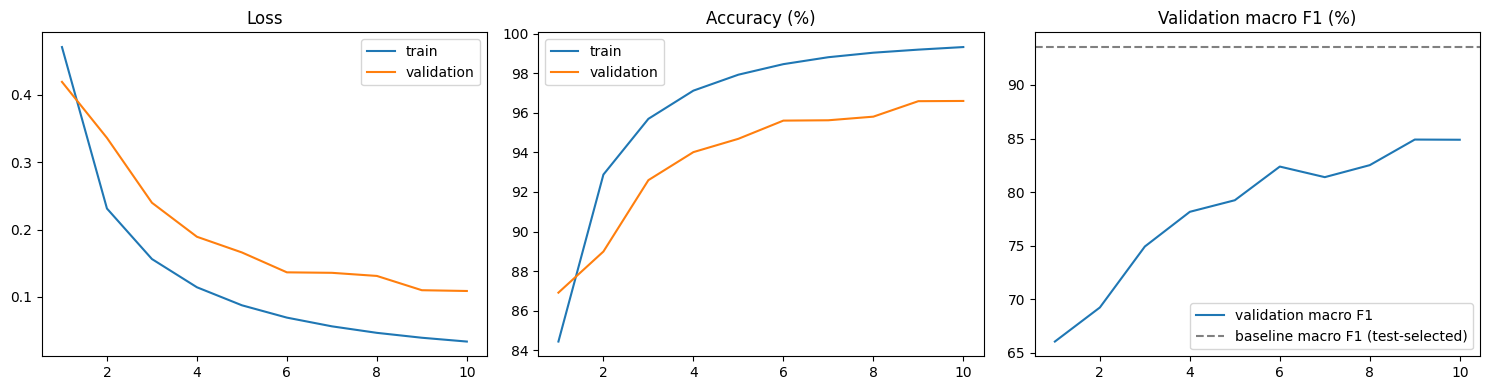

In [28]:
hist_path = os.path.join(RESULTS_DIR, "kan_history_pilot.csv")
if os.path.exists(hist_path):
    h = pd.read_csv(hist_path)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="validation")
    ax[0].set_title("Loss"); ax[0].legend()
    ax[1].plot(h.epoch, h.train_accuracy, label="train"); ax[1].plot(h.epoch, h.val_accuracy, label="validation")
    ax[1].set_title("Accuracy (%)"); ax[1].legend()
    ax[2].plot(h.epoch, h.val_macro_f1, label="validation macro F1")
    ax[2].axhline(BASELINE["macro_f1"], ls="--", color="gray", label="baseline macro F1 (test-selected)")
    ax[2].set_title("Validation macro F1 (%)"); ax[2].legend()
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, "kan_learning_curve.png"), dpi=150)
    plt.show()
else:
    print("Belum ada history pilot.")

## 9. Keputusan pilot
Aturan (ASUMSI, heuristik): **PROMISING** jika validation macro F1 terbaik berada dalam `PILOT_TOLERANCE_PP` poin dari baseline **dan** kurva masih naik dalam 3 epoch terakhir. Perbandingan ini tidak sebanding sepenuhnya, karena baseline dihitung pada test set.

In [29]:
hist_path = os.path.join(RESULTS_DIR, "kan_history_pilot.csv")
if os.path.exists(hist_path):
    h = pd.read_csv(hist_path)
    best_row = h.loc[h["val_macro_f1"].idxmax()]
    improving = len(h) >= 4 and h["val_macro_f1"].iloc[-1] > h["val_macro_f1"].iloc[-4]
    near_baseline = best_row["val_macro_f1"] >= BASELINE["macro_f1"] - PILOT_TOLERANCE_PP
    PILOT_DECISION = "PROMISING" if (near_baseline and improving) else "NOT PROMISING"

    print("BEST PILOT VALIDATION")
    print(f"  epoch            : {int(best_row['epoch'])}")
    print(f"  accuracy         : {best_row['val_accuracy']:.2f}")
    print(f"  macro precision  : {best_row['val_macro_precision']:.2f}")
    print(f"  macro recall     : {best_row['val_macro_recall']:.2f}")
    print(f"  macro F1         : {best_row['val_macro_f1']:.2f}")
    print(f"Baseline macro F1  : {BASELINE['macro_f1']:.2f} (test-selected, bukan validation)")
    print(f"Naik 3 epoch terakhir: {improving}")
    print("DECISION (pilot):", PILOT_DECISION)
else:
    print("NOT RUN: belum ada history pilot.")

BEST PILOT VALIDATION
  epoch            : 9
  accuracy         : 96.59
  macro precision  : 80.64
  macro recall     : 90.93
  macro F1         : 84.90
Baseline macro F1  : 93.53 (test-selected, bukan validation)
Naik 3 epoch terakhir: True
DECISION (pilot): NOT PROMISING


## 10. Full training 150 epoch (terkunci)
Hanya berjalan jika `RUN_FULL_TRAINING = True` **dan** keputusan pilot `PROMISING`.

In [30]:
if RUN_FULL_TRAINING:
    if PILOT_DECISION != "PROMISING":
        raise RuntimeError("Full training diblokir: keputusan pilot bukan PROMISING (atau pilot belum dijalankan).")
    full_hist = fit(EPOCHS_FULL, "full")
    full_hist.to_csv(os.path.join(RESULTS_DIR, "kan_history.csv"), index=False)
else:
    print("NOT RUN: full training terkunci (RUN_FULL_TRAINING = False)")

NOT RUN: full training terkunci (RUN_FULL_TRAINING = False)


## 11. Evaluasi final pada test set (sekali)
Memuat `full_best_validation_macro_f1.pt`, yang dipilih berdasarkan validation. Test set hanya dipakai di sini.

In [31]:
if RUN_FINAL_EVALUATION:
    best_path = os.path.join(CKPT_DIR, "full_best_validation_macro_f1.pt")
    if not os.path.exists(best_path):
        raise FileNotFoundError("Checkpoint full belum ada. Jalankan full training terlebih dahulu.")
    st = torch.load(best_path, map_location=DEVICE, weights_only=False)
    model = KAN().to(DEVICE)
    model.load_state_dict(st["model"])

    t0 = time.time()
    _, y_true_test, y_pred_test = evaluate(model, test_loader)
    infer_total_s = time.time() - t0

    FINAL = compute_metrics(y_true_test, y_pred_test)
    FINAL["checkpoint_epoch"] = st["epoch"]
    FINAL["inference_time_per_sample_ms"] = 1000 * infer_total_s / len(y_true_test)
    print({k: round(float(v), 4) for k, v in FINAL.items()})

    pd.DataFrame([FINAL]).to_csv(os.path.join(RESULTS_DIR, "kan_test_metrics.csv"), index=False)
    rep = classification_report(y_true_test, y_pred_test, target_names=CLASS_NAMES,
                                output_dict=True, zero_division=0)
    pd.DataFrame(rep).T.to_csv(os.path.join(RESULTS_DIR, "kan_classification_report.csv"))
    cm = confusion_matrix(y_true_test, y_pred_test, labels=range(N_CLASSES))
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        os.path.join(RESULTS_DIR, "kan_confusion_matrix.csv"))
    per_class_recall = recall_score(y_true_test, y_pred_test, average=None, labels=range(N_CLASSES), zero_division=0)

    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(5)); ax.set_xticklabels(CLASS_NAMES)
    ax.set_yticks(range(5)); ax.set_yticklabels(CLASS_NAMES)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
    ax.set_title("KAN confusion matrix (test)")
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "kan_confusion_matrix.png"), dpi=150); plt.show()

    fig, ax = plt.subplots(figsize=(5, 3.5))
    ax.bar(CLASS_NAMES, 100 * per_class_recall)
    ax.set_ylabel("Recall (%)"); ax.set_title("KAN per-class recall (test)")
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "kan_per_class_recall.png"), dpi=150); plt.show()
else:
    print("NOT RUN: set RUN_FINAL_EVALUATION = True setelah full training selesai")

NOT RUN: set RUN_FINAL_EVALUATION = True setelah full training selesai


## 12. Perbandingan dengan baseline
Selisih dalam poin persentase (KAN − baseline). Keputusan hanya dibuat jika evaluasi final sudah dijalankan.

**Catatan keadilan:** baseline ResNet18+GAF (Tabel A notebook `01_replikasi`) memilih checkpoint berdasarkan test set. KAN memilih berdasarkan validation. Perbandingan ini cenderung menguntungkan baseline.

In [32]:
if FINAL is not None:
    rows = []
    for key, label in [("accuracy", "Accuracy"), ("macro_precision", "Macro Precision"),
                       ("macro_recall", "Macro Recall"), ("macro_f1", "Macro F1")]:
        rows.append({"metric": label, "baseline_resnet18_gaf": BASELINE[key],
                     "kan": FINAL[key], "difference_pp": FINAL[key] - BASELINE[key]})
    comp = pd.DataFrame(rows)
    comp.to_csv(os.path.join(RESULTS_DIR, "kan_vs_baseline.csv"), index=False)
    print(comp.round(2).to_string(index=False))

    superior = any(FINAL[k] > BASELINE[k] for k in BASELINE)
    COMPARISON_DECISION = "SUPERIOR ON AT LEAST ONE METRIC" if superior else "DOES NOT EXCEED BASELINE"
    print("\nDECISION:", COMPARISON_DECISION)
else:
    print("NOT RUN: belum ada evaluasi final.")

NOT RUN: belum ada evaluasi final.


## 13. Efisiensi dan log eksperimen

In [33]:
efficiency = {
    "kan_total_params": N_PARAMS_TOTAL,
    "kan_trainable_params": N_PARAMS_TRAINABLE,
    "baseline_total_params": BASELINE_PARAMS_TOTAL,
    "baseline_params_note": "dihitung: ResNet18 torchvision 11,689,512 - fc 513,000 + head 512-256-128-5 = 11,341,125 (verifikasi aritmetika)",
}
hist_files = [f for f in ("kan_history_pilot.csv", "kan_history.csv") if os.path.exists(os.path.join(RESULTS_DIR, f))]
if hist_files:
    h = pd.read_csv(os.path.join(RESULTS_DIR, hist_files[-1]))
    efficiency["mean_epoch_time_s"] = float(h["epoch_time_s"].mean())
else:
    efficiency["mean_epoch_time_s"] = "NOT RUN"
efficiency["inference_time_per_sample_ms"] = FINAL["inference_time_per_sample_ms"] if FINAL else "NOT RUN"

log = {
    "paper": "Cui et al. 2025, Algorithms 18(2):90, DOI 10.3390/a18020090 (inspirasi, bukan replikasi exact)",
    "paper_reported_mitbih": {"accuracy": 99.08, "precision": 99.07, "recall": 98.99, "f1": 99.03,
                              "note": "PAPER-REPORTED, protokol split tidak dijelaskan; bukan hasil eksperimen ini"},
    "paper_params_verified": {"input": 187, "hidden": 128, "output": 5, "lr": 5e-5, "optimizer": "Adam",
                              "batch": 64, "epochs": 150, "scale_spline": 1.0, "grid_eps": 0.02,
                              "activation": "SiLU", "grid_range": [-1, 1], "spline": "quadratic (order 2)"},
    "assumptions": {"grid_size": GRID_SIZE, "variance_order_direction": "ascending",
                    "pilot_tolerance_pp": PILOT_TOLERANCE_PP,
                    "spline_init": "noise_scale 0.1 x scale_spline",
                    "balancing": "random oversampling with replacement, training split only, target = majority count"},
    "deviations": {"grid_eps": "not applied (no adaptive grid update)",
                   "library": "custom minimal KAN implementation, no pykan",
                   "split": "stratified 80/20 of raw train (random_state=42)"},
    "baseline_caveat": "baseline checkpoint selected on test set (notebook 01 Table A); KAN selects on validation",
    "environment": {"torch": torch.__version__, "numpy": np.__version__, "sklearn": sklearn.__version__,
                    "device": str(DEVICE),
                    "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None},
    "seed": SEED,
    "flags": {"RUN_SMOKE_TEST": RUN_SMOKE_TEST, "RUN_PILOT": RUN_PILOT,
              "RUN_FULL_TRAINING": RUN_FULL_TRAINING, "RUN_FINAL_EVALUATION": RUN_FINAL_EVALUATION},
    "smoke_status": SMOKE_STATUS,
    "pilot_decision": PILOT_DECISION,
    "comparison_decision": COMPARISON_DECISION,
    "final_test_metrics": FINAL,
    "efficiency": efficiency,
}
with open(os.path.join(RESULTS_DIR, "kan_experiment_log.json"), "w") as f:
    json.dump(log, f, indent=2, default=str)
print("Log tersimpan:", os.path.join(RESULTS_DIR, "kan_experiment_log.json"))

Log tersimpan: /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/outputs/results/kan_experiment_log.json


In [34]:
print("=" * 42)
print("KAN EXPERIMENT SUMMARY")
print("=" * 42)
print("CREATED: notebooks/08_kan_pilot.ipynb")
print()
print("PAPER (PAPER-REPORTED, bukan hasil kita): Acc 99.08 | P 99.07 | R 98.99 | F1 99.03")
print(f"BASELINE (test-selected): Acc {BASELINE['accuracy']} | P {BASELINE['macro_precision']} | "
      f"R {BASELINE['macro_recall']} | F1 {BASELINE['macro_f1']}")
print()
if SMOKE_STATUS:
    print("SMOKE TEST:", "PASS" if all(v == "PASS" for v in SMOKE_STATUS.values()) else "FAIL")
else:
    print("SMOKE TEST: NOT RUN")
print("PILOT:", "RUN" if RUN_PILOT else "NOT RUN")
if os.path.exists(os.path.join(RESULTS_DIR, "kan_history_pilot.csv")):
    hp = pd.read_csv(os.path.join(RESULTS_DIR, "kan_history_pilot.csv"))
    print(f"BEST VALIDATION MACRO F1: {hp['val_macro_f1'].max():.2f} (epoch {int(hp.loc[hp['val_macro_f1'].idxmax(), 'epoch'])})")
else:
    print("BEST VALIDATION MACRO F1: NOT RUN")
print("DECISION (pilot):", PILOT_DECISION or "NOT RUN")
print("FINAL TEST:", "RUN" if FINAL else "NOT RUN")
print("COMPARISON:", COMPARISON_DECISION or "NOT RUN")
print("FULL TRAINING:", "RUN" if RUN_FULL_TRAINING else "NOT RUN")

KAN EXPERIMENT SUMMARY
CREATED: notebooks/08_kan_pilot.ipynb

PAPER (PAPER-REPORTED, bukan hasil kita): Acc 99.08 | P 99.07 | R 98.99 | F1 99.03
BASELINE (test-selected): Acc 98.86 | P 95.23 | R 91.97 | F1 93.53

SMOKE TEST: NOT RUN
PILOT: RUN
BEST VALIDATION MACRO F1: 84.90 (epoch 9)
DECISION (pilot): NOT PROMISING
FINAL TEST: NOT RUN
COMPARISON: NOT RUN
FULL TRAINING: NOT RUN


## Catatan metodologi (wajib dibaca)
1. **Bukan replikasi exact.** Split 80/20, balancing random oversampling (bukan repeated random sampling paper), `GRID_SIZE=5`, arah variance sorting naik, dan threshold keputusan pilot adalah asumsi atau pilihan proyek. Lihat `kan_experiment_log.json`.
2. **Baseline dipilih pada test set.** Angka 98.86 / 95.23 / 91.97 / 93.53 adalah Tabel A (checkpoint epoch 21 dipilih dari test). Untuk perbandingan yang lebih adil, bandingkan juga dengan epoch terakhir baseline dari `final_results_final_epoch.csv` (notebook `01_replikasi`).
3. **Distribusi training berbeda.** Baseline memakai SMOTE (152.471 sampel). KAN memakai random oversampling pada training split 80% dari data mentah.
4. **Paper-reported 99.08% tidak sebanding.** Protokol split paper tidak dijelaskan, dan dataset paper memakai angka yang tidak dapat diverifikasi dari teks.
5. **Full training hanya jika pilot PROMISING.** Notebook tidak dijalankan secara otomatis.